# GRAZPEDWRI-DX · Image EDA

Numerička analiza pokušava da obradi sve slike iz četiri arhive. Galerije koriste mali, reproduktivan izbor originala.

## 1. Inventar četiri arhive

**Istraživačko pitanje.** Da li lokalne arhive pokrivaju CSV identifikatore?

**Postupak.** Čitamo ZIP direktorijume bez raspakivanja. Poredimo broj članova, jedinstvene ključeve i poklapanje sa CSV-om.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

from wrist_fracture.data.eda import link_annotations, missing_table, source_fingerprint
from wrist_fracture.data.eda_settings import (
    DATASET, SEED, USE_CACHE, analytical_images, load_inputs, stratified_examples,
)
from wrist_fracture.visualization.image_eda import show_gallery_pages

sns.set_theme(style='whitegrid', palette='deep', rc={
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 4)
root, csv_path, annotation_path, metadata, audit, index, index_issues = load_inputs()
linked = link_annotations(metadata, audit)
images = analytical_images(metadata, audit, index)
expected = set(metadata.filestem.dropna())
indexed = set(index.filestem)
valid_boxes = audit.boxes.loc[audit.boxes.valid]

def summary(**values):
    display(Markdown('**Numerički sažetak**'))
    display(pd.Series(values, name='vrednost').to_frame())

def plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

from pathlib import Path
from wrist_fracture.data.image_eda import measure_images

archive_counts = index.groupby(index.source.map(lambda source: Path(source).name)).filestem.agg(
    članovi='size', jedinstveni='nunique')
display(archive_counts, index_issues)
duplicate_count = int(index.filestem.duplicated(keep=False).sum())
summary(izvor=DATASET, očekivani_CSV_ID=len(expected), arhive=len(archive_counts),
        članovi=len(index), jedinstveni_ID=len(indexed), dvosmisleni_članovi=duplicate_count,
        CSV_bez_slike=len(expected - indexed), slike_bez_CSV=len(indexed - expected))

,članovi,jedinstveni
source,,
images_part1.zip,5031,5031
images_part2.zip,5143,5143
images_part3.zip,4842,4842
images_part4.zip,5311,5311


,source,issue


**Numerički sažetak**

,vrednost
izvor,GRAZPEDWRI-DX v2
očekivani_CSV_ID,20327
arhive,4
članovi,20327
jedinstveni_ID,20327
dvosmisleni_članovi,0
CSV_bez_slike,0
slike_bez_CSV,0


<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 2. Dekodiranje i obuhvat merenja

**Istraživačko pitanje.** Koliko slika možemo da dekodiramo i numerički analiziramo?

**Postupak.** Obrađujemo svaki jednoznačan slikovni identifikator. Završene serije čuvamo u JSON kešu. Izvorne vrednosti piksela ostaju u sačuvanoj dubini.

In [2]:
metrics, problems, state = measure_images(
    images, limit=None, seed=SEED, hashes=False,
    cache_dir=root / 'results/cache/image_eda' if USE_CACHE else None,
    context={'dataset': DATASET})
measured = images.merge(metrics.drop(columns='filestem'), on='image_key', validate='one_to_one')
measured['megapixels'] = measured.width_px * measured.height_px / 1e6
coverage = ('potpun za grayscale metrike' if index_issues.empty and len(index) == len(expected)
            and indexed == expected and len(measured) == len(expected)
            and measured.get('pixel_mean', pd.Series(dtype=float)).count() == len(expected)
            else 'delimičan')
display(problems.issue.value_counts().rename('zabeleženi problemi').to_frame(), problems.head(10))
display(pd.DataFrame([{'skup': DATASET, 'potpis': state['signature'],
                       'seed': SEED, 'keš uključen': USE_CACHE}]))
summary(obuhvat=coverage, očekivano=len(expected), indeksirano=len(index), pokušano=state['selected'],
        dekodirano=len(measured), neuspešno_dekodiranje=state['selected'] - len(measured),
        grayscale_metrike=int(measured.get('pixel_mean', pd.Series(dtype=float)).count()),
        evidentirani_problemi=len(problems))
if measured.empty:
    raise RuntimeError('Nema dekodiranih slika za tehničke analize. Proverite inventar i tabelu problema.')

,zabeleženi problemi
issue,


,image_key,filestem,issue


,skup,potpis,seed,keš uključen
0,GRAZPEDWRI-DX v2,6d3d054267aaa818b934d2cfad52ad41a71a5012fec134...,42,True


**Numerički sažetak**

,vrednost
obuhvat,potpun za grayscale metrike
očekivano,20327
indeksirano,20327
pokušano,20327
dekodirano,20327
neuspešno_dekodiranje,0
grayscale_metrike,20327
evidentirani_problemi,0


<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 3. Dimenzije i rezolucija

**Istraživačko pitanje.** Koliko se razlikuju širina, visina i format kadra?

**Postupak.** Računamo širinu i visinu u pikselima, površinu u megapikselima i odnos širine i visine za sve dekodirane slike.

,count,mean,std,min,25%,50%,75%,max
width_px,20327.0,562.7914,129.3166,212.0000,476.0000,549.0000,632.0000,1664.0000
height_px,20327.0,1009.1214,205.7125,324.0000,865.5000,999.0000,1144.0000,2328.0000
megapixels,20327.0,0.5797,0.2212,0.0826,0.4296,0.5445,0.6917,3.0950
aspect_ratio,20327.0,0.5701,0.1307,0.2480,0.4799,0.5572,0.6430,1.6793


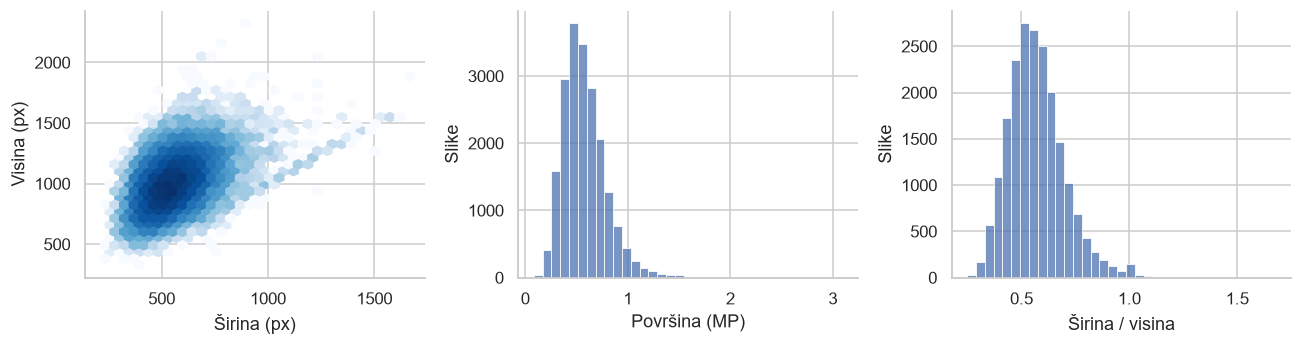

**Numerički sažetak**

,vrednost
dekodirane_slike,20327.0000
medijana_širine_px,549.0000
medijana_visine_px,999.0000
medijana_odnosa,0.5572


In [3]:
dim = ['width_px', 'height_px', 'megapixels', 'aspect_ratio']
display(measured[dim].describe().T)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hexbin(measured.width_px, measured.height_px, gridsize=32, mincnt=1, bins='log', cmap='Blues')
axes[0].set(xlabel='Širina (px)', ylabel='Visina (px)')
for ax, col, label in zip(axes[1:], dim[2:], ['Površina (MP)', 'Širina / visina']):
    sns.histplot(measured[col], bins=35, ax=ax)
    ax.set(xlabel=label, ylabel='Slike')
plot(fig)
summary(dekodirane_slike=len(measured), medijana_širine_px=measured.width_px.median(),
        medijana_visine_px=measured.height_px.median(), medijana_odnosa=round(measured.aspect_ratio.median(), 4))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 4. Format, bit depth i tip piksela

**Istraživačko pitanje.** U kom formatu i preciznosti su slike sačuvane?

**Postupak.** Dubinu čitamo iz zaglavlja, a režim i dtype iz dekodiranog prikaza. Prikazujemo i broj kanala i broj frejmova.

In [4]:
format_columns = ['format', 'stored_bits', 'mode', 'dtype', 'channels', 'frames']
display(measured.groupby(format_columns, dropna=False).size().rename('slike').to_frame())
summary(dekodirano=len(measured), sačuvano_16_bit=int(measured.stored_bits.eq(16).sum()),
        nepoznata_dubina=int(measured.stored_bits.eq('unknown').sum()),
        jedan_kanal=int(measured.channels.eq(1).sum()),
        više_frejmova=int(measured.frames.gt(1).sum()))

,,,,,,slike
format,stored_bits,mode,dtype,channels,frames,
PNG,16,I;16,uint16,1,1,20327


**Numerički sažetak**

,vrednost
dekodirano,20327
sačuvano_16_bit,20327
nepoznata_dubina,0
jedan_kanal,20327
više_frejmova,0


<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 5. Intenziteti u izvornim DN jedinicama

**Istraživačko pitanje.** Kako se raspoređuju intenziteti između slika?

**Postupak.** Prikazujemo statistike po slici na originalnim pikselima. Grafikoni raspodeljuju per-image metrike. Medijana per-image srednjih vrednosti opisuje tipičnu sliku.

,izmereno,mean,std,min,25%,50%,75%,max
pixel_min,20327.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000
pixel_max,20327.0,65534.9994,0.0243,65534.0000,65535.0000,65535.0000,65535.000,65535.0000
observed_range,20327.0,65534.9994,0.0243,65534.0000,65535.0000,65535.0000,65535.000,65535.0000
pixel_mean,20327.0,19551.3386,4152.9972,2001.0151,16752.0169,19545.6264,22315.988,42146.5059
pixel_median,20327.0,19492.6095,5014.1328,0.0000,16593.5000,19644.0000,22671.000,45909.0000
pixel_std,20327.0,11376.6565,2174.3805,2306.8701,9821.7486,11215.0929,13006.667,20322.9894
p01,20327.0,734.3419,1855.7085,0.0000,0.0000,0.0000,0.000,19572.0000
p05,20327.0,2597.7236,3222.7986,0.0000,0.0000,0.0000,5184.500,26646.0000
p95,20327.0,38373.4972,6283.4061,6033.0000,33592.0000,38101.0000,43157.000,58606.0000
p99,20327.0,46847.7730,7235.3623,7890.0000,41225.0000,47483.0000,53028.500,65535.0000


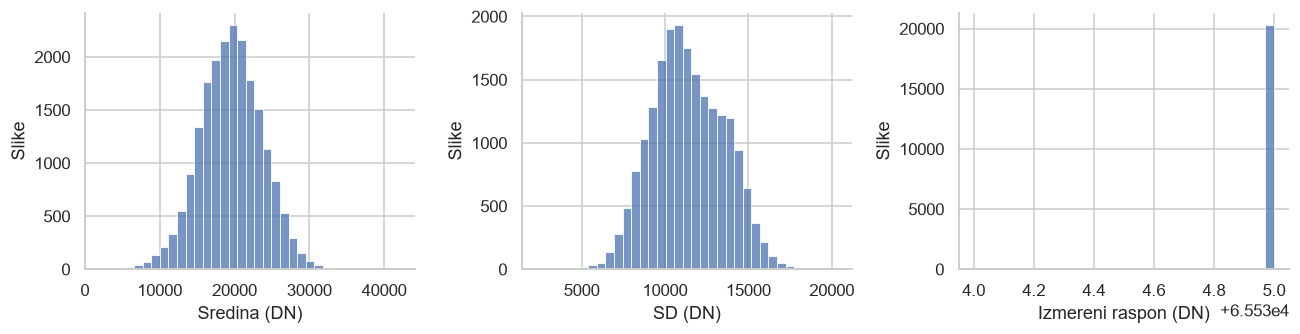

**Numerički sažetak**

,vrednost
izmerene_grayscale_slike,20327.00
bez_DN_metrika,0.00
medijana_srednjih_intenziteta_DN,19545.63


In [5]:
dn = ['pixel_min', 'pixel_max', 'observed_range', 'pixel_mean', 'pixel_median',
      'pixel_std', 'p01', 'p05', 'p95', 'p99']
display(measured.reindex(columns=dn).describe().T.rename(columns={'count': 'izmereno'}))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, label in zip(axes, ['pixel_mean', 'pixel_std', 'observed_range'],
                          ['Sredina (DN)', 'SD (DN)', 'Izmereni raspon (DN)']):
    sns.histplot(measured.reindex(columns=[col])[col], bins=35, ax=ax)
    ax.set(xlabel=label, ylabel='Slike')
plot(fig)
means = measured.reindex(columns=['pixel_mean']).pixel_mean
summary(izmerene_grayscale_slike=int(means.count()), bez_DN_metrika=int(means.isna().sum()),
        medijana_srednjih_intenziteta_DN=round(means.median(), 2))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 6. Osvetljenost, kontrast i tehnički kvalitet

**Istraživačko pitanje.** Koliko se razlikuju tonalitet, kontrast i proxy oštrine?

**Postupak.** Kontrast P99–P1 i sredinu merimo i kao udeo teorijskog unsigned raspona. Udeli blizu krajeva koriste donjih i gornjih 1%. Varijansa Laplasijana je tehnička aproksimacija oštrine i zavisi i od rezolucije. Full-scale pokazatelji su dostupni za podržan unsigned raspon. Laplasijan zahteva raster veličine bar 3 × 3.

,izmereno,mean,std,min,25%,50%,75%,max
contrast_p99_p01,20327.0,46113.4311,7426.0287,7.8900e+03,4.0521e+04,4.6775e+04,52370.5000,65535.0000
mean_fullscale,20327.0,0.2983,0.0634,3.0534e-02,2.5562e-01,2.9825e-01,0.3405,0.6431
contrast_fullscale,20327.0,0.7036,0.1133,1.2039e-01,6.1831e-01,7.1374e-01,0.7991,1.0000
near_zero_fraction,20327.0,0.0788,0.0873,2.0529e-06,1.9210e-02,5.3293e-02,0.1076,0.7340
near_ceiling_fraction,20327.0,0.0002,0.0003,4.1250e-07,1.3943e-05,4.6953e-05,0.0003,0.0113
laplacian_variance,20327.0,0.0021,0.0010,3.6903e-04,1.4583e-03,1.8825e-03,0.0024,0.0137


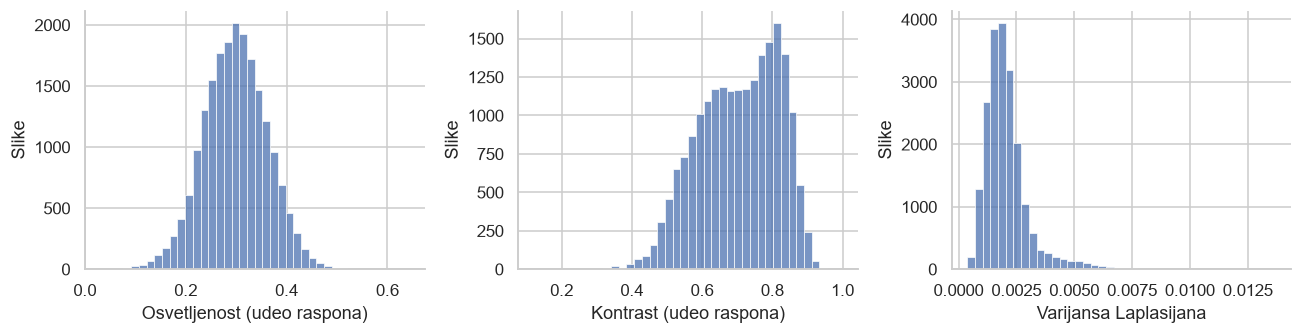

**Numerički sažetak**

,vrednost
izmeren_kontrast_DN,20327.0
unsigned_normalizacija,20327.0
proxy_oštrine,20327.0
bez_unsigned_normalizacije,0.0
bez_proxy_oštrine,0.0
medijana_kontrasta_DN,46775.0


In [6]:
quality = ['contrast_p99_p01', 'mean_fullscale', 'contrast_fullscale',
           'near_zero_fraction', 'near_ceiling_fraction', 'laplacian_variance']
q = measured.reindex(columns=quality)
display(q.describe().T.rename(columns={'count': 'izmereno'}))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, label in zip(axes, ['mean_fullscale', 'contrast_fullscale', 'laplacian_variance'],
                          ['Osvetljenost (udeo raspona)', 'Kontrast (udeo raspona)', 'Varijansa Laplasijana']):
    sns.histplot(q[col], bins=40, ax=ax)
    ax.set(xlabel=label, ylabel='Slike')
plot(fig)
summary(izmeren_kontrast_DN=int(q.contrast_p99_p01.count()),
        unsigned_normalizacija=int(q.mean_fullscale.count()), proxy_oštrine=int(q.laplacian_variance.count()),
        bez_unsigned_normalizacije=int(q.mean_fullscale.isna().sum()),
        bez_proxy_oštrine=int(q.laplacian_variance.isna().sum()),
        medijana_kontrasta_DN=round(q.contrast_p99_p01.median(), 2))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 7. Poređenje po projekciji i proizvođaču

**Istraživačko pitanje.** Kako tehničke mere izgledaju u izvornim grupama?

**Postupak.** Za svaku grupu prikazujemo broj slika, broj dostupnih vrednosti i medijane. Poređenja su deskriptivna i kodovi projekcije ostaju izvorni.

,slike,megapixels · n,pixel_mean · n,contrast_fullscale · n,laplacian_variance · n,megapixels · medijana,pixel_mean · medijana,contrast_fullscale · medijana,laplacian_variance · medijana
projection,,,,,,,,,
1,10086,10086,10086,10086,10086,0.5913,19597.4667,0.6840,0.0020
2,10148,10148,10148,10148,10148,0.5017,19516.3731,0.7588,0.0018
3,93,93,93,93,93,0.4943,17310.8395,0.6970,0.0019


,slike,megapixels · n,pixel_mean · n,contrast_fullscale · n,laplacian_variance · n,megapixels · medijana,pixel_mean · medijana,contrast_fullscale · medijana,laplacian_variance · medijana
device_manufacturer,,,,,,,,,
Agfa,112,112,112,112,112,1.1102,8929.5161,0.6648,0.0022
Siemens,20215,20215,20215,20215,20215,0.5433,19571.3530,0.7143,0.0019


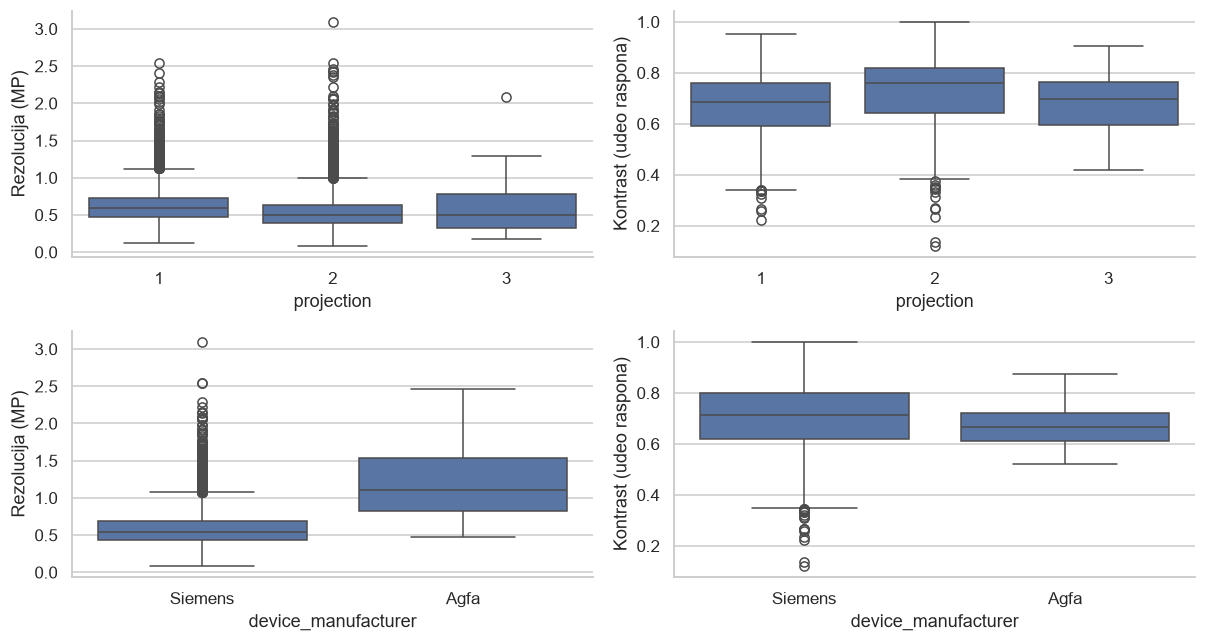

**Numerički sažetak**

,vrednost
dekodirane_slike,20327
najmanja_projekcija_n,93
najmanji_proizvođač_n,112


In [7]:
features = ['megapixels', 'pixel_mean', 'contrast_fullscale', 'laplacian_variance']
frame = measured.reindex(columns=['projection', 'device_manufacturer', *features])
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
group_sizes = {}
for i, key in enumerate(['projection', 'device_manufacturer']):
    grouped = frame.groupby(key, dropna=False)
    group_sizes[key] = grouped.size()
    display(pd.concat([grouped.size().rename('slike'), grouped[features].count().add_suffix(' · n'),
                       grouped[features].median().add_suffix(' · medijana')], axis=1))
    for j, metric in enumerate(['megapixels', 'contrast_fullscale']):
        plot_frame = frame.assign(**{key: frame[key].astype('string').fillna('nedostaje')})
        sns.boxplot(data=plot_frame, x=key, y=metric, ax=axes[i, j])
        axes[i, j].set(xlabel=key, ylabel={'megapixels': 'Rezolucija (MP)',
                                          'contrast_fullscale': 'Kontrast (udeo raspona)'}[metric])
plot(fig)
summary(dekodirane_slike=len(measured), najmanja_projekcija_n=int(group_sizes['projection'].min()),
        najmanji_proizvođač_n=int(group_sizes['device_manufacturer'].min()))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 8. Tehničke anomalije i ekstremi

**Istraživačko pitanje.** Koji snimci se nalaze na krajevima tehničkih raspodela?

**Postupak.** Biramo determinističke minimume i maksimume za rezoluciju, odnos stranica, intenzitet i kontrast, uz najniži proxy oštrine. Razlozi izbora prate svaki prikaz.

,filestem,reason
0,1387_1012595124_01_WRI-L2_F001,minimum: rezolucija (MP) (0.08263)
1,5391_0667332742_01_WRI-L2_M014,maksimum: rezolucija (MP) (3.095)
2,2796_0758211815_01_WRI-R2_F008,minimum: širina / visina (0.248)
3,1296_0590400053_01_WRI-L1_F005,maksimum: širina / visina (1.679)
4,1110_1201775970_03_WRI-L2_M008,minimum: srednji intenzitet (DN) (2001)
5,0818_0571828119_04_WRI-R1_M013,maksimum: srednji intenzitet (DN) (4.215e+04)
6,2964_0926436692_02_WRI-L2_F012,minimum: kontrast (0.1204)
7,1524_0639700228_01_WRI-R2_F017,maksimum: kontrast (1)
8,2964_0926436692_02_WRI-L2_F012,minimum: proxy oštrine (0.000369)


,image_key,filestem,issue


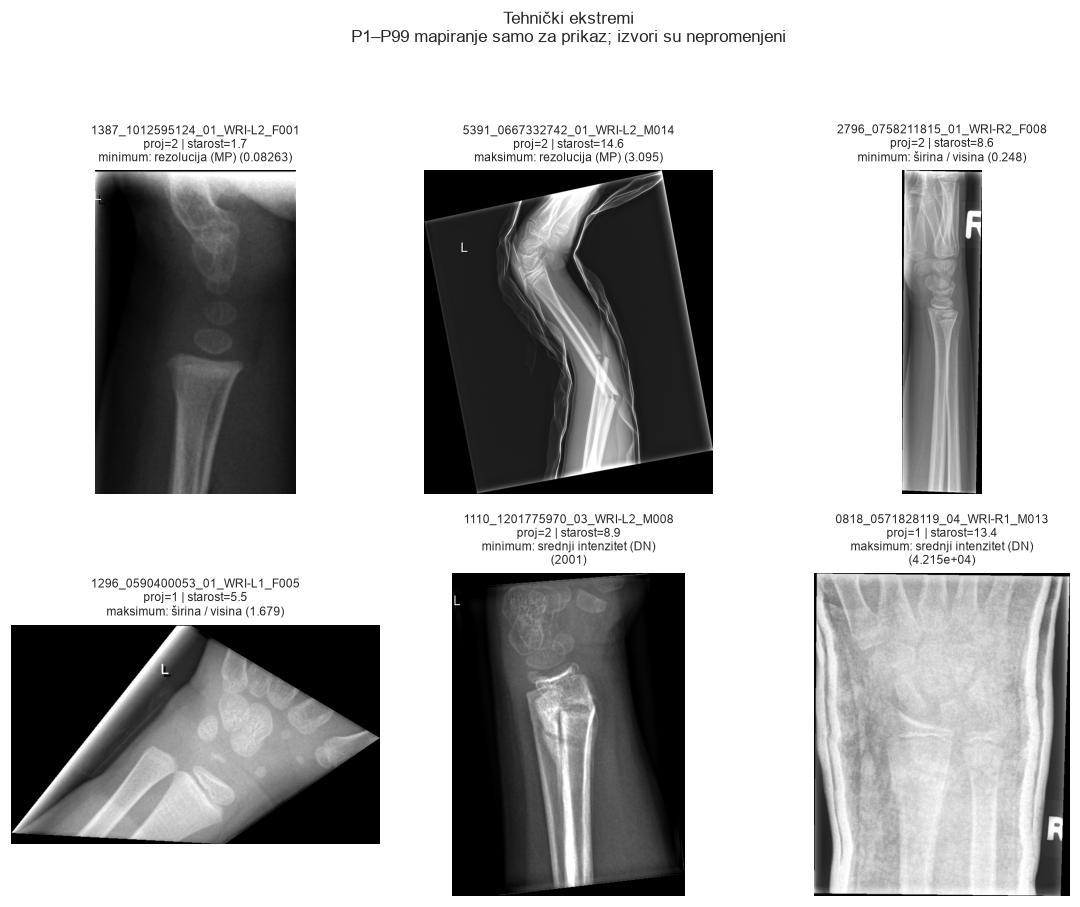

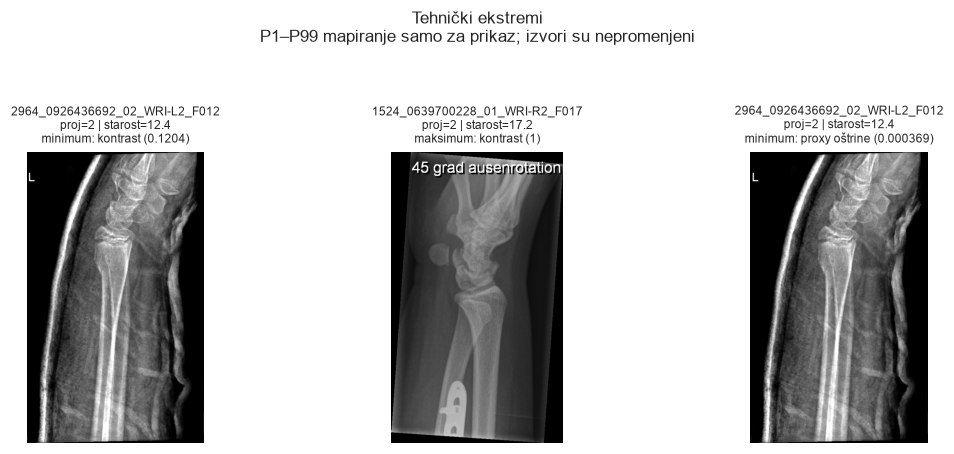

**Numerički sažetak**

,vrednost
ukupno_dekodirano,20327
razlozi_izbora,9
jedinstvene_slike,8
evidentirani_problemi,0


In [8]:
edge_parts = []
for col, label, high in [('megapixels', 'rezolucija (MP)', True),
                         ('aspect_ratio', 'širina / visina', True),
                         ('pixel_mean', 'srednji intenzitet (DN)', True),
                         ('contrast_fullscale', 'kontrast', True),
                         ('laplacian_variance', 'proxy oštrine', False)]:
    if col not in measured:
        continue
    ordered = measured.dropna(subset=[col]).sort_values([col, 'image_key'])
    if not ordered.empty:
        extremes = [('minimum', ordered.head(1))]
        if high:
            extremes.append(('maksimum', ordered.tail(1)))
        for side, part in extremes:
            edge_parts.append(part.assign(reason=f'{side}: {label} ({part[col].iloc[0]:.4g})'))
technical = pd.concat(edge_parts, ignore_index=True)
display(technical[['filestem', 'reason']], problems.head(10))
show_gallery_pages(technical, audit.boxes, audit.classes, title='Tehnički ekstremi')
summary(ukupno_dekodirano=len(measured), razlozi_izbora=len(technical),
        jedinstvene_slike=technical.filestem.nunique(), evidentirani_problemi=len(problems))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 9. Reprezentativni primeri originala

**Istraživačko pitanje.** Kako izgledaju snimci iz različitih dostupnih grupa?

**Postupak.** Biramo po jedan primer iz svakog zatečenog preseka projekcije i proizvođača i po jedan iz unapred navedenih raspona uzrasta. P1–P99 skaliranje je samo za prikaz.

,filestem,projection,device_manufacturer,age,reason
0,0133_0282914262_06_WRI-R1_M014,1,Agfa,14.2,projection=1 | device_manufacturer=Agfa
1,1986_0261107189_02_WRI-L1_M006,1,Siemens,6.4,projection=1 | device_manufacturer=Siemens
2,2980_0565365685_01_WRI-R2_F009,2,Agfa,9.0,projection=2 | device_manufacturer=Agfa
3,3732_0858458488_01_WRI-R2_F013,2,Siemens,13.0,projection=2 | device_manufacturer=Siemens
4,3195_1002525454_01_WRI-L3_M004,3,Siemens,4.0,projection=3 | device_manufacturer=Siemens
5,4378_0206807942_01_WRI-R2_M006,2,Siemens,6.0,uzrast=≤6
6,3994_0482391606_02_WRI-L1_M010,1,Siemens,10.9,uzrast=>6 do 12
7,4174_0221111536_03_WRI-L1_M017,1,Siemens,17.6,uzrast=>12


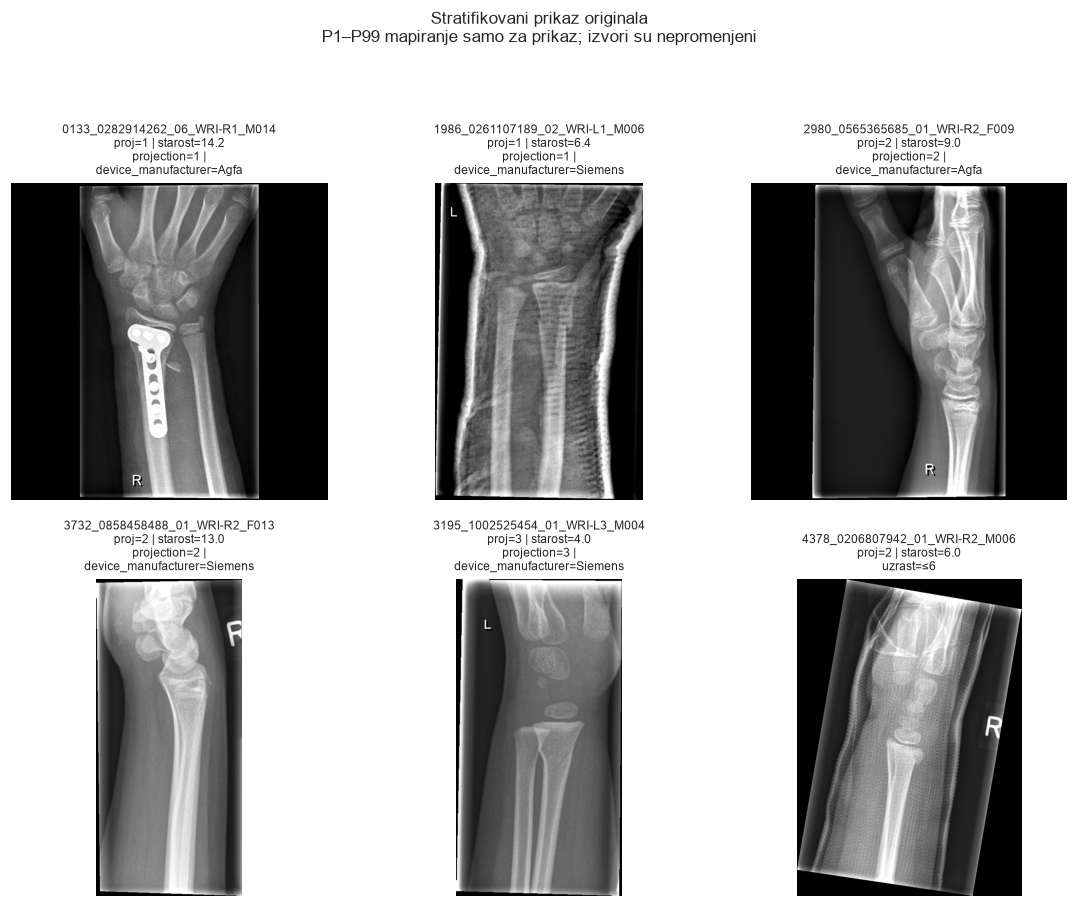

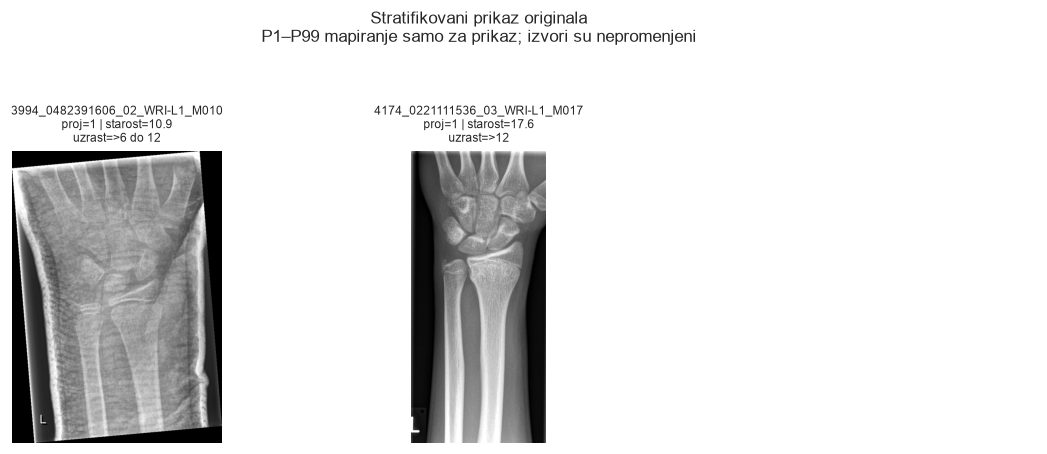

**Numerički sažetak**

,vrednost
seed,42
stratifikovani_prikazi,8
jedinstvene_stratifikovane_slike,8
ciljani_prikazi,9


In [9]:
with_age = measured.assign(uzrast=pd.cut(measured.age, [-np.inf, 6, 12, np.inf],
                                       labels=['≤6', '>6 do 12', '>12']))
representative = pd.concat([
    stratified_examples(measured, ['projection', 'device_manufacturer']),
    stratified_examples(with_age, ['uzrast']),
], ignore_index=True)
display(representative[['filestem', 'projection', 'device_manufacturer', 'age', 'reason']])
show_gallery_pages(representative, audit.boxes, audit.classes, title='Stratifikovani prikaz originala')
selection = pd.concat([representative.assign(izbor='stratifikovan'), technical.assign(izbor='ciljan')])
selection_dir = root / 'results/eda_review'
selection_dir.mkdir(parents=True, exist_ok=True)
selection.assign(seed=SEED, potpis=state['signature'], skup=DATASET)[
    ['filestem', 'member', 'izbor', 'reason', 'seed', 'potpis', 'skup']
].to_csv(selection_dir / 'image_gallery_selection.csv', index=False, encoding='utf-8-sig')
summary(seed=SEED, stratifikovani_prikazi=len(representative),
        jedinstvene_stratifikovane_slike=representative.filestem.nunique(),
        ciljani_prikazi=len(technical))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 10. Završni numerički pregled

**Istraživačko pitanje.** Koji rezultati opisuju tehnički pregled?

**Postupak.** Objedinjujemo inventar, pokrivenost merenja, sačuvanu dubinu i odabrane deskriptivne mere.

In [10]:
summary(obuhvat=coverage, očekivano=len(expected), indeksirano=len(index), pokušano=state['selected'],
        dekodirano=len(measured), grayscale_metrike=int(means.count()),
        sačuvano_16_bit=int(measured.stored_bits.eq(16).sum()),
        medijana_rezolucije_MP=round(measured.megapixels.median(), 4),
        medijana_srednjih_intenziteta_DN=round(means.median(), 2),
        medijana_kontrasta_DN=round(q.contrast_p99_p01.median(), 2))

**Numerički sažetak**

,vrednost
obuhvat,potpun za grayscale metrike
očekivano,20327
indeksirano,20327
pokušano,20327
dekodirano,20327
grayscale_metrike,20327
sačuvano_16_bit,20327
medijana_rezolucije_MP,0.5445
medijana_srednjih_intenziteta_DN,19545.63
medijana_kontrasta_DN,46775.0


<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>